# Ridgeline → Metallicity Regression

Predict a globular cluster's [Fe/H] from its HUGS RGB ridgelines.

- Each cluster has 2 ridge files (x-axis: `F814W_abs` or `F438W_abs`), each tracing all 5C2 = 10 colors, so 20 ridge maps per cluster.
- Magnitudes in the ridge files are already absolute (distances were applied upstream), so `GC_distances.csv` is not needed here.
- Labels: Harris (2010) [Fe/H] in `data/GC_metallicity_harris.csv`.
- With ~55 clusters we sample each ridge at a few fixed absolute magnitudes (where all clusters overlap) and fit a small, regularised linear model, validated leave-one-cluster-out.

In [1]:
import os, re, zipfile, io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid', context='notebook')

PROJECT_DIR = Path().resolve()
PROJECT_ROOT_NAME = 'spectroscopy-regression'
while PROJECT_DIR.name != PROJECT_ROOT_NAME and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)
PROJECT_DIR

WindowsPath('C:/Users/phucl/Research/gc/spectroscopy-regression')

## Load labels and ridgelines

In [2]:
labels = pd.read_csv('data/GC_metallicity_harris.csv').set_index('NGC')['Fe/H_harris']

BANDS = ['F814W', 'F438W']
ridges = {b: {} for b in BANDS}   # ridges[band][ngc] -> DataFrame (high-confidence rows only)
n_total = {b: {} for b in BANDS}

with zipfile.ZipFile('data/GC Ridgelines.zip') as zf:
    for name in zf.namelist():
        m = re.search(r'NGC(\d+)_(F\d+W)_ridge\.csv$', name)
        if not m:
            continue
        ngc, band = int(m.group(1)), m.group(2)
        d = pd.read_csv(io.BytesIO(zf.read(name)))
        n_total[band][ngc] = len(d)
        d = d[d['low_conf'].astype(str) == 'False'].drop(columns='low_conf').dropna()
        if len(d) >= 2:
            ridges[band][ngc] = d.sort_values(f'{band}_abs')

COLORS = [c for c in next(iter(ridges['F814W'].values())).columns if '-' in c]
print(len(COLORS), 'colors:', COLORS)
for b in BANDS:
    print(b, 'clusters with usable ridge:', len(ridges[b]), 'of', len(n_total[b]))
print('clusters without a label:', sorted((set(ridges['F814W']) | set(ridges['F438W'])) - set(labels.index)))

10 colors: ['F275W-F336W', 'F275W-F438W', 'F275W-F606W', 'F275W-F814W', 'F336W-F438W', 'F336W-F606W', 'F336W-F814W', 'F438W-F606W', 'F438W-F814W', 'F606W-F814W']
F814W clusters with usable ridge: 54 of 56
F438W clusters with usable ridge: 42 of 54
clusters without a label: []


## Ridgelines coloured by metallicity

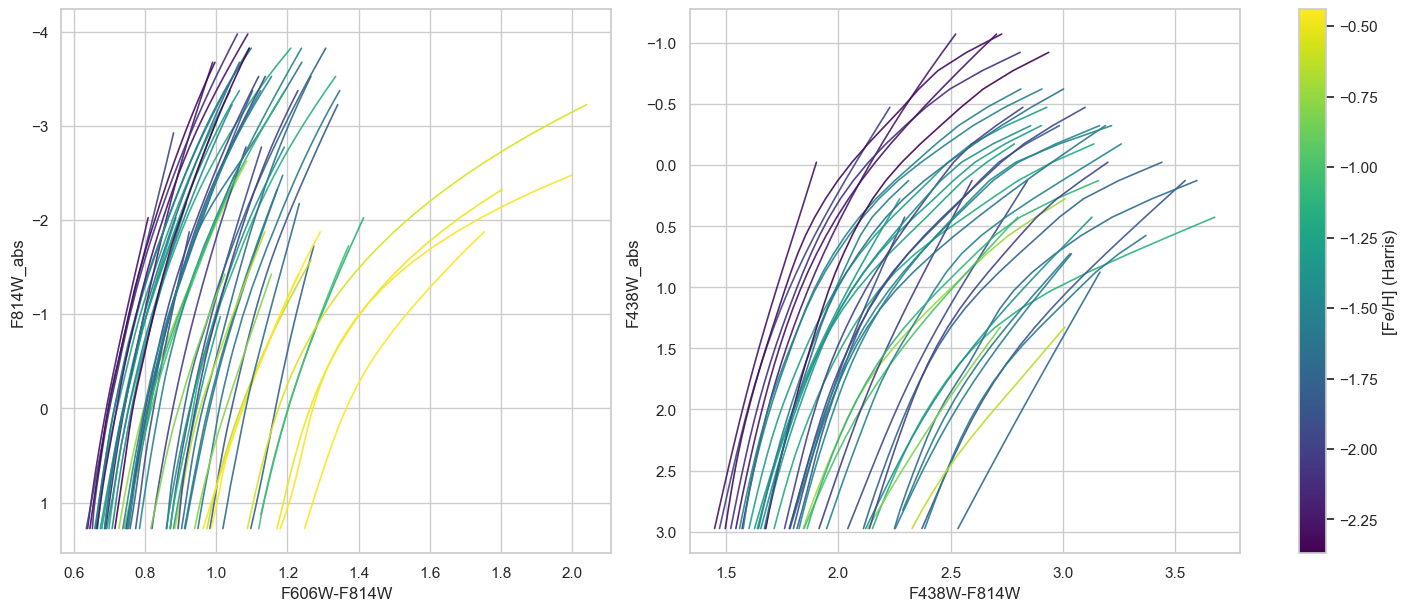

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
norm = plt.Normalize(labels.min(), labels.max())
cmap = plt.cm.viridis
for ax, (band, color) in zip(axes, [('F814W', 'F606W-F814W'), ('F438W', 'F438W-F814W')]):
    for ngc, d in ridges[band].items():
        ax.plot(d[color], d[f'{band}_abs'], color=cmap(norm(labels[ngc])), lw=1.2, alpha=0.9)
    ax.invert_yaxis()
    ax.set_xlabel(color); ax.set_ylabel(f'{band}_abs')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, label='[Fe/H] (Harris)')
plt.show()

## Choose a sampling grid

We only interpolate (never extrapolate) inside each cluster's high-confidence range. Let's see which absolute magnitudes are covered by most clusters.

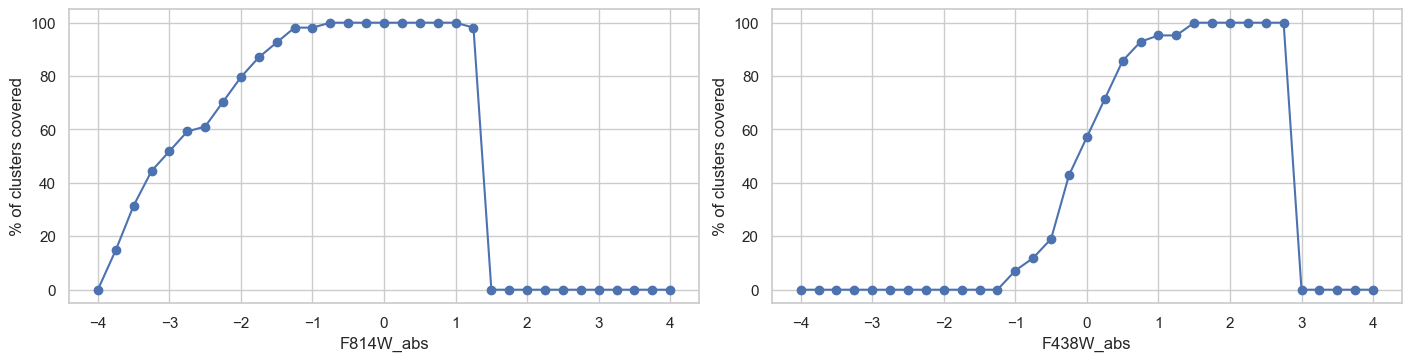

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), constrained_layout=True)
for ax, band in zip(axes, BANDS):
    grid = np.arange(-4, 4.01, 0.25)
    cov = [np.mean([d[f'{band}_abs'].min() <= g <= d[f'{band}_abs'].max() for d in ridges[band].values()]) for g in grid]
    ax.plot(grid, np.array(cov) * 100, marker='o')
    ax.set_xlabel(f'{band}_abs'); ax.set_ylabel('% of clusters covered')
plt.show()

In [5]:
# Grid chosen from the coverage curves above (keep points covered by most clusters)
GRID = {
    'F814W': [-0.5, 0.0, 0.5, 1.0],
    'F438W': [1.5, 2.0, 2.5],
}

def sample_ridge(d, band, m, color):
    x = d[f'{band}_abs'].to_numpy()
    if m < x.min() or m > x.max():
        return np.nan
    return float(np.interp(m, x, d[color].to_numpy()))

all_ngc = sorted(set(ridges['F814W']) | set(ridges['F438W']))
rows = {}
for ngc in all_ngc:
    feats = {}
    for band in BANDS:
        d = ridges[band].get(ngc)
        for m in GRID[band]:
            for color in COLORS:
                feats[f'{band}@{m:+.1f}|{color}'] = np.nan if d is None else sample_ridge(d, band, m, color)
    rows[ngc] = feats

X_all = pd.DataFrame.from_dict(rows, orient='index')
X_all.index.name = 'NGC'
print('raw feature matrix:', X_all.shape)

# Drop features that are missing for too many clusters, and clusters missing most features
nan_frac_feat = X_all.isna().mean()
X = X_all.loc[:, nan_frac_feat <= 0.3]
keep = X.isna().mean(axis=1) <= 0.5
print('dropped clusters (mostly missing features):', list(X.index[~keep]))
X = X[keep]
y = labels.loc[X.index]
print('final:', X.shape, 'mean NaN fraction:', round(X.isna().to_numpy().mean(), 3))

raw feature matrix: (54, 70)
dropped clusters (mostly missing features): []
final: (54, 70) mean NaN fraction: 0.095


## Models, validated leave-one-cluster-out

Imputation and scaling are inside the pipeline so nothing leaks from the held-out cluster. Ridge picks its penalty with built-in LOO; PLS picks its number of components with an inner 5-fold CV.

In [6]:
def scores(name, y_true, y_pred):
    return dict(model=name,
                RMSE=np.sqrt(mean_squared_error(y_true, y_pred)),
                MAE=mean_absolute_error(y_true, y_pred),
                R2=r2_score(y_true, y_pred))

prep = lambda: [SimpleImputer(strategy='median'), StandardScaler()]
models = {
    'baseline (mean)': make_pipeline(DummyRegressor()),
    'Ridge (all features)': make_pipeline(*prep(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
    'PLS': make_pipeline(*prep(), GridSearchCV(PLSRegression(scale=False), {'n_components': [1, 2, 3, 4, 5]}, cv=5)),
}

preds, results = {}, []
for name, model in models.items():
    preds[name] = np.ravel(cross_val_predict(model, X, y, cv=LeaveOneOut()))
    results.append(scores(name, y, preds[name]))
pd.DataFrame(results).set_index('model').round(3)

,RMSE,MAE,R2
model,,,
baseline (mean),0.552,0.454,-0.038
Ridge (all features),0.161,0.131,0.912
PLS,0.176,0.142,0.895


### Does the choice of band/colour matter? Ridge on subsets

In [7]:
def ridge_loo(cols):
    m = make_pipeline(*prep(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
    p = cross_val_predict(m, X[cols], y, cv=LeaveOneOut())
    return np.sqrt(mean_squared_error(y, p))

subsets = {
    'F814W axis only': [c for c in X if c.startswith('F814W@')],
    'F438W axis only': [c for c in X if c.startswith('F438W@')],
    'optical colours (no F275W/F336W)': [c for c in X if not re.search('F275W|F336W', c.split('|')[1])],
    'UV-involving colours': [c for c in X if re.search('F275W|F336W', c.split('|')[1])],
}
pd.Series({k: ridge_loo(v) for k, v in subsets.items()}, name='LOO RMSE').round(3)

F814W axis only                     0.180
F438W axis only                     0.288
optical colours (no F275W/F336W)    0.266
UV-involving colours                0.212
Name: LOO RMSE, dtype: float64

### Single-feature baselines (best individual colour)

In [8]:
single = {}
for c in X:
    xi = X[[c]]
    if xi.isna().mean().iloc[0] > 0.1:
        continue
    m = make_pipeline(*prep(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
    single[c] = np.sqrt(mean_squared_error(y, cross_val_predict(m, xi, y, cv=LeaveOneOut())))
single = pd.Series(single).sort_values()
single.head(10).round(3)

F814W@-0.5|F275W-F336W    0.256
F814W@-0.5|F275W-F438W    0.262
F814W@+0.0|F275W-F336W    0.263
F814W@+0.5|F275W-F336W    0.268
F814W@+0.0|F275W-F438W    0.269
F814W@+1.0|F275W-F336W    0.271
F814W@+0.5|F275W-F438W    0.273
F814W@+1.0|F275W-F438W    0.276
F814W@-0.5|F336W-F438W    0.286
F814W@-0.5|F275W-F606W    0.290
dtype: float64

## Predicted vs. true [Fe/H]

best model: Ridge (all features)


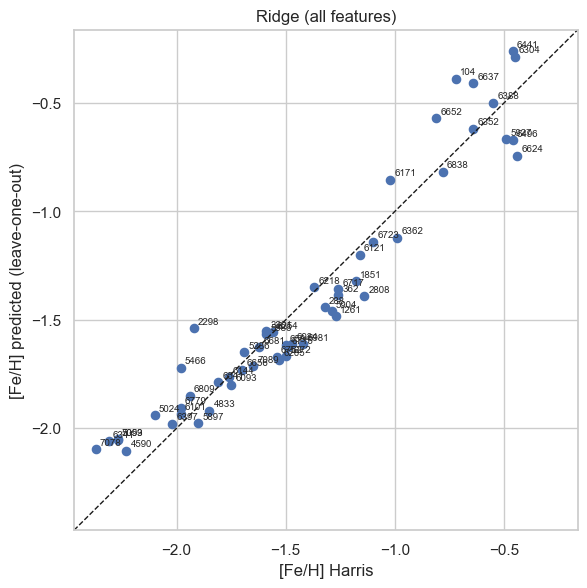

largest residuals (pred - true):
NGC
6624   -0.30
2808   -0.25
6496   -0.21
7078    0.27
104     0.33
2298    0.38
dtype: float64


In [9]:
best = min(results[1:], key=lambda r: r['RMSE'])['model']
print('best model:', best)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
p = preds[best]
ax.scatter(y, p, s=35)
for ngc, yt, yp in zip(y.index, y, p):
    ax.annotate(str(ngc), (yt, yp), fontsize=7, xytext=(3, 3), textcoords='offset points')
lim = [min(y.min(), p.min()) - 0.1, max(y.max(), p.max()) + 0.1]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('[Fe/H] Harris'); ax.set_ylabel('[Fe/H] predicted (leave-one-out)')
ax.set_title(best)
plt.show()

resid = pd.Series(p - y.to_numpy(), index=y.index).sort_values()
print('largest residuals (pred - true):'); print(resid.iloc[[0, 1, 2, -3, -2, -1]].round(2))

## Which ridge features carry the signal?

Standardised ridge coefficients from a fit on all clusters (for interpretation only, not for scoring).

In [10]:
final = make_pipeline(*prep(), RidgeCV(alphas=np.logspace(-2, 3, 30))).fit(X, y)
coef = pd.Series(final[-1].coef_, index=X.columns)
print('chosen alpha:', final[-1].alpha_)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).round(3)

chosen alpha: 3.856620421163472


F814W@+1.0|F606W-F814W   -0.076
F814W@+0.5|F606W-F814W   -0.074
F438W@+1.5|F606W-F814W   -0.065
F814W@-0.5|F606W-F814W   -0.064
F814W@+0.0|F606W-F814W   -0.064
F438W@+2.0|F606W-F814W   -0.063
F438W@+2.5|F606W-F814W   -0.052
F438W@+2.5|F336W-F438W    0.051
F814W@+0.0|F336W-F438W    0.050
F814W@+0.5|F336W-F438W    0.049
F814W@-0.5|F336W-F438W    0.045
F814W@-0.5|F275W-F438W    0.044
F814W@+1.0|F336W-F438W    0.043
F814W@-0.5|F275W-F336W    0.042
F814W@-0.5|F275W-F606W    0.039
dtype: float64

## Notes / next steps

- Harris [Fe/H] carries ~0.1 dex scale uncertainty, which sets a floor on achievable RMSE.
- Clusters with sparse or all-low-confidence ridges are dropped or median-imputed; check the printed lists above.
- Possible improvements: ridge slope / curvature features, a low-order polynomial fit per map, or propagating distance errors into the absolute magnitudes.